In [42]:
import pandas as pd
# from src.weighted_metrics import weighted_pct  # Di-comment karena modul 'src' tidak ditemukan dan fungsi tidak digunakan di sel ini

df = pd.read_csv("integrated_respondents_private.csv")

# Sanity check
assert len(df) == 1068
assert df["wgt"].notna().all()

bench = {"anydigpayment": 42.69, "internet_use": 70.46,
         "saved": 52.99, "borrowed": 47.64}
for col, target in bench.items():
    val = (df["wgt"] * df[col]).sum() / df["wgt"].sum() * 100
    print(col, round(val, 2), "OK" if abs(val - target) < 0.01 else "CEK")

# Populasi hambatan
barrier_pop = df[df["account_fin"] == 0]
assert len(barrier_pop) == 504

anydigpayment 42.69 OK
internet_use 70.46 OK
saved 52.99 OK
borrowed 47.64 OK


In [43]:
def weighted_rate(d, col):
    valid = d[d[col].isin([0, 1])]
    if valid["wgt"].sum() == 0:
        return pd.Series({"weighted_pct": None, "n_valid": 0})
    pct = (valid["wgt"] * valid[col]).sum() / valid["wgt"].sum() * 100
    return pd.Series({"weighted_pct": round(pct, 2), "n_valid": len(valid)})

indicators = ["anydigpayment", "internet_use", "account_mob", "saved", "borrowed"]
dimensions = ["gender", "age_group", "education", "income_quintile", "residence"]

rows = []
for ind in indicators:
    # Total nasional
    r = weighted_rate(df, ind)
    rows.append({"indicator": ind, "dimension": "National", "category": "All", **r})
    # Per dimensi
    for dim in dimensions:
        for cat, g in df.groupby(dim, dropna=False):
            r = weighted_rate(g, ind)
            rows.append({"indicator": ind, "dimension": dim,
                         "category": cat, **r})

adoption = pd.DataFrame(rows)
adoption["small_sample"] = adoption["n_valid"] < 50  # tandai kelompok kecil

In [44]:
nat = adoption[adoption.dimension == "National"].set_index("indicator")["weighted_pct"]
print(nat)   # harus 42.69, 70.46, 52.99, 47.64 untuk empat indikator, dan 22.01 untuk account_mob

indicator
anydigpayment    42.69
internet_use     70.46
account_mob      22.01
saved            52.99
borrowed         47.64
Name: weighted_pct, dtype: float64


In [27]:
# Internet vs non-internet untuk pembayaran digital
div = adoption.query("indicator=='anydigpayment' and dimension=='internet_group'")

In [28]:
a = weighted_rate(df[df.internet_group == "Internet user"], "anydigpayment")
b = weighted_rate(df[df.internet_group == "Non-internet user"], "anydigpayment")
gap_internet_pp = a["weighted_pct"] - b["weighted_pct"]

q1 = weighted_rate(df[df.income_quintile == "Q1 - lowest"], "anydigpayment")
q5 = weighted_rate(df[df.income_quintile == "Q5 - highest"], "anydigpayment")
gap_q5_q1_pp = q5["weighted_pct"] - q1["weighted_pct"]

In [29]:
barrier_labels = {
    "fin11a": "Lembaga keuangan terlalu jauh",
    "fin11b": "Biaya layanan keuangan terlalu mahal",
    "fin11c": "Kurangnya dokumen yang diperlukan",
    "fin11d": "Tidak memiliki cukup uang",
    "fin11e": "Anggota keluarga sudah memiliki rekening",
    "fin11f": "Kurangnya kepercayaan terhadap lembaga keuangan",
}

In [30]:
print("Internet user    :", a["weighted_pct"], "| n =", a["n_valid"])
print("Non-internet user:", b["weighted_pct"], "| n =", b["n_valid"])
print("Gap internet (pp):", round(gap_internet_pp, 2))
print()
print("Q1 :", q1["weighted_pct"], "| n =", q1["n_valid"])
print("Q5 :", q5["weighted_pct"], "| n =", q5["n_valid"])
print("Gap Q5-Q1 (pp):", round(gap_q5_q1_pp, 2))
print()
display(barriers)

Internet user    : 53.38 | n = 736.0
Non-internet user: 17.21 | n = 332.0
Gap internet (pp): 36.17

Q1 : 33.83 | n = 210.0
Q5 : 66.83 | n = 244.0
Gap Q5-Q1 (pp): 33.0



,barrier,weighted_pct,n_valid
3,Tidak memiliki cukup uang,63.76,502
4,Anggota keluarga sudah memiliki rekening,52.28,493
1,...,51.54,484
0,...,39.74,495
2,...,33.38,500
5,Kurangnya kepercayaan terhadap lembaga keuangan,17.78,491


In [31]:
display(adoption[adoption.dimension == "National"])

,indicator,dimension,category,weighted_pct,n_valid,small_sample
0,anydigpayment,National,All,42.69,1068.0,False
19,internet_use,National,All,70.46,1068.0,False
38,account_mob,National,All,22.01,1068.0,False
57,saved,National,All,52.99,1068.0,False
76,borrowed,National,All,47.64,1068.0,False


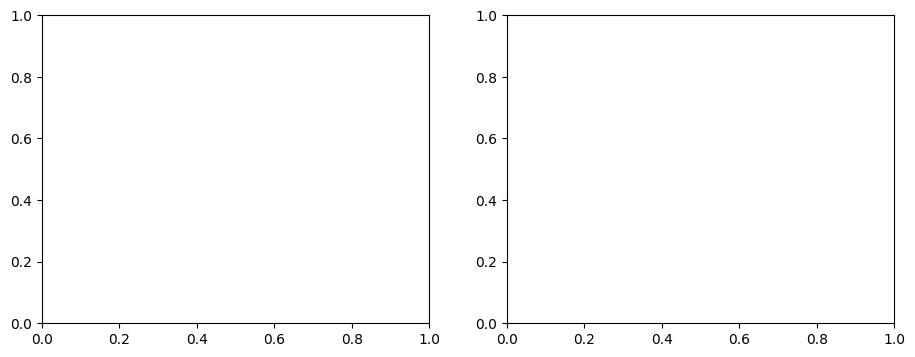

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

internet = adoption.query("indicator=='anydigpayment' and dimension=='internet_group'")

In [33]:
ax[0].bar(internet["category"], internet["weighted_pct"])
ax[0].set_title("Pembayaran digital menurut penggunaan internet")
ax[0].set_ylabel("% berbobot")

inc = adoption.query("indicator=='anydigpayment' and dimension=='income_quintile'").sort_values("category")
ax[1].bar(inc["category"], inc["weighted_pct"])
ax[1].set_title("Pembayaran digital menurut kuintil pendapatan")
ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

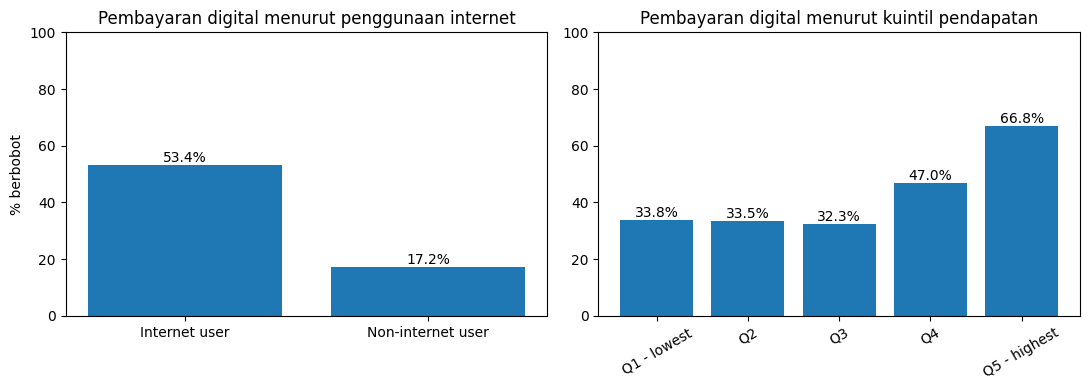

In [34]:
import matplotlib.pyplot as plt

internet = adoption.query("indicator=='anydigpayment' and dimension=='internet_group'")
inc = (adoption.query("indicator=='anydigpayment' and dimension=='income_quintile'")
               .sort_values("category"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].bar(internet["category"], internet["weighted_pct"])
ax[0].set_title("Pembayaran digital menurut penggunaan internet")
ax[0].set_ylabel("% berbobot")

ax[1].bar(inc["category"], inc["weighted_pct"])
ax[1].set_title("Pembayaran digital menurut kuintil pendapatan")
ax[1].tick_params(axis="x", rotation=30)

for a in ax:
    a.set_ylim(0, 100)
    for p in a.patches:
        a.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                   ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [35]:
print(adoption["dimension"].unique())

['National' 'gender' 'age_group' 'education' 'income_quintile' 'residence'
 'internet_group']


In [36]:
rows = []
for ind in indicators:
    for cat, g in df.groupby("internet_group", dropna=False):
        r = weighted_rate(g, ind)
        rows.append({"indicator": ind, "dimension": "internet_group",
                     "category": cat, **r})

extra = pd.DataFrame(rows)
extra["small_sample"] = extra["n_valid"] < 50

adoption = pd.concat([adoption, extra], ignore_index=True)
print(adoption["dimension"].unique())

['National' 'gender' 'age_group' 'education' 'income_quintile' 'residence'
 'internet_group']


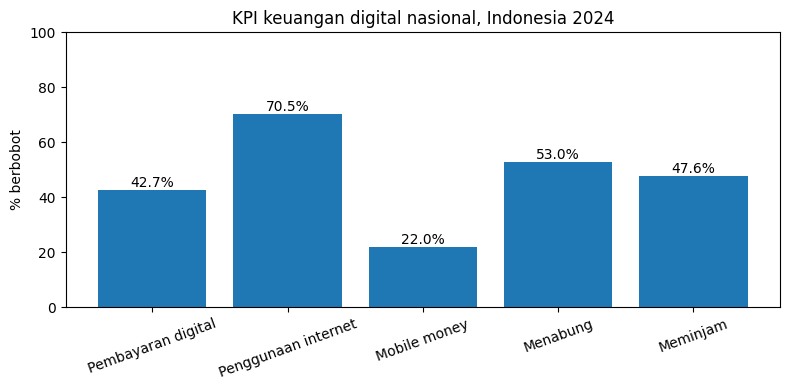

In [37]:
import matplotlib.pyplot as plt

nat = adoption.query("dimension=='National'").set_index("indicator").loc[indicators]
labels = {"anydigpayment": "Pembayaran digital", "internet_use": "Penggunaan internet",
          "account_mob": "Mobile money", "saved": "Menabung", "borrowed": "Meminjam"}

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([labels[i] for i in nat.index], nat["weighted_pct"])
ax.set_title("KPI keuangan digital nasional, Indonesia 2024")
ax.set_ylabel("% berbobot")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=20)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

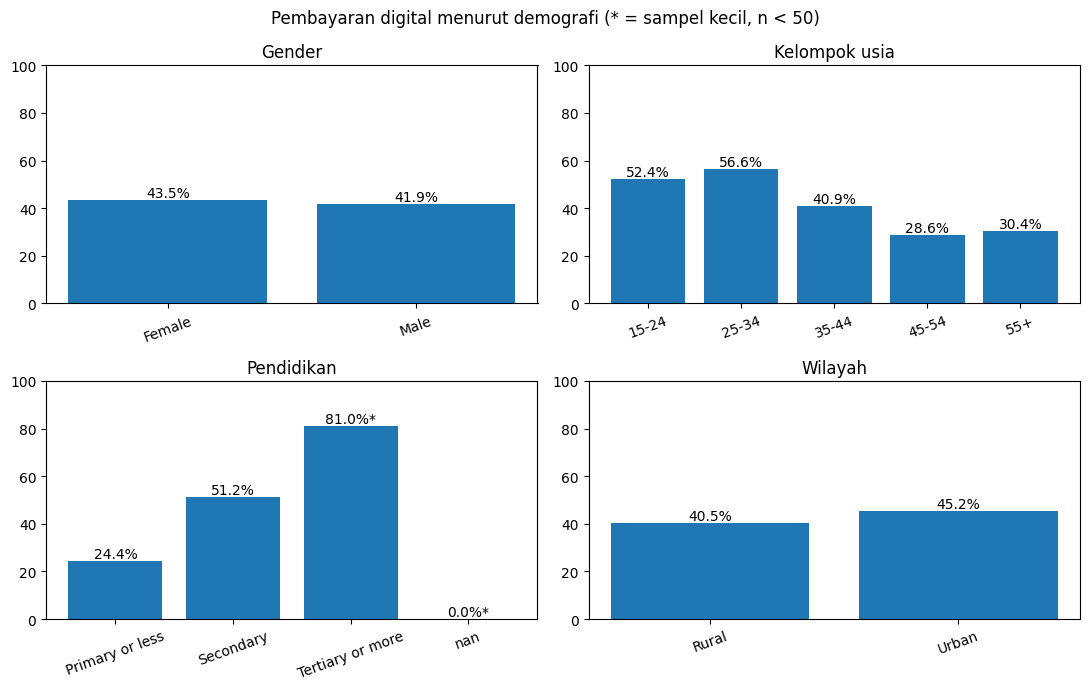

In [38]:
dims = {"gender": "Gender", "age_group": "Kelompok usia",
        "education": "Pendidikan", "residence": "Wilayah"}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for a, (dim, title) in zip(axes.flat, dims.items()):
    d = adoption.query("indicator=='anydigpayment' and dimension==@dim").sort_values("category")
    a.bar(d["category"].astype(str), d["weighted_pct"])
    a.set_title(title)
    a.set_ylim(0, 100)
    a.tick_params(axis="x", rotation=20)
    for p, small in zip(a.patches, d["small_sample"]):
        txt = f"{p.get_height():.1f}%" + ("*" if small else "")
        a.annotate(txt, (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
fig.suptitle("Pembayaran digital menurut demografi (* = sampel kecil, n < 50)")
plt.tight_layout()
plt.show()

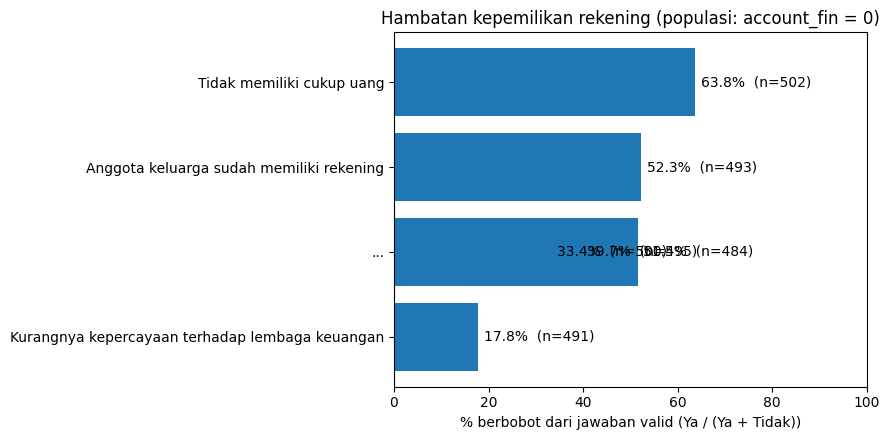

In [39]:
b = barriers.sort_values("weighted_pct")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(b["barrier"], b["weighted_pct"])
ax.set_xlim(0, 100)
ax.set_xlabel("% berbobot dari jawaban valid (Ya / (Ya + Tidak))")
ax.set_title("Hambatan kepemilikan rekening (populasi: account_fin = 0)")
for p, n in zip(ax.patches, b["n_valid"]):
    ax.annotate(f"{p.get_width():.1f}%  (n={n})", (p.get_width(), p.get_y() + p.get_height()/2),
                va="center", xytext=(4, 0), textcoords="offset points")
plt.tight_layout()
plt.show()

In [40]:
adoption.to_csv("p2_adoption_agg.csv", index=False)
barriers.to_csv("p2_barriers_agg.csv", index=False)

In [41]:
barrier_labels = {
    "fin11a": "Lembaga keuangan terlalu jauh",
    "fin11b": "Biaya layanan keuangan terlalu mahal",
    "fin11c": "Kurangnya dokumen yang diperlukan",
    "fin11d": "Tidak memiliki cukup uang",
    "fin11e": "Anggota keluarga sudah memiliki rekening",
    "fin11f": "Kurangnya kepercayaan terhadap lembaga keuangan",
}